In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn = the most famous machine learning library in Python
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('/titanic_cleaned.csv')
print("Dataset loaded:", df.shape[0], "passengers")
df.head()

Dataset loaded: 891 passengers


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [3]:
# 'male'/'female' are words — the model can't do math with words!
# So we convert: male = 1, female = 0
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})

# 'Embarked' has 3 values (C/Q/S) — convert to numbers too (one-hot encoding)
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

# X = the questions (features the model learns from)
# y = the answer key (what we want to predict)
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
X = df[features]
y = df['Survived']

print(X.head())
print("\nTarget y: 1 = survived, 0 = did not survive")

   Pclass  Sex   Age  SibSp  Parch     Fare  Embarked_Q  Embarked_S
0       3    1  22.0      1      0   7.2500       False        True
1       1    0  38.0      1      0  71.2833       False       False
2       3    0  26.0      0      0   7.9250       False        True
3       1    0  35.0      1      0  53.1000       False        True
4       3    1  35.0      0      0   8.0500       False        True

Target y: 1 = survived, 0 = did not survive


In [4]:
# 80% for training (practice), 20% for testing (exam)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training passengers:", X_train.shape[0])
print("Testing passengers:", X_test.shape[0])

Training passengers: 712
Testing passengers: 179


In [5]:
model = LogisticRegression(max_iter=1000)

# .fit() = the model studies 712 passengers and learns the patterns
model.fit(X_train, y_train)

print("Model trained successfully! ✅")

Model trained successfully! ✅


In [6]:
# Predict on the 179 test passengers it has NEVER seen
y_pred = model.predict(X_test)

# Compare predictions vs reality for the first 10 passengers
comparison = pd.DataFrame({
    'Actual (reality)': y_test.values[:10],
    'Predicted (model)': y_pred[:10]
})
print(comparison)

   Actual (reality)  Predicted (model)
0                 1                  0
1                 0                  0
2                 0                  0
3                 1                  1
4                 1                  1
5                 1                  1
6                 1                  1
7                 0                  0
8                 1                  1
9                 1                  1


In [7]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.1f}%")

Model Accuracy: 81.0%


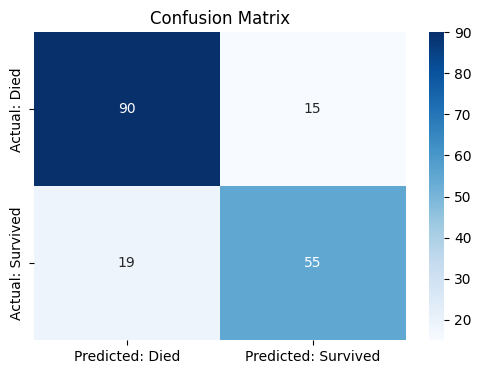

In [8]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted: Died', 'Predicted: Survived'],
            yticklabels=['Actual: Died', 'Actual: Survived'])
plt.title('Confusion Matrix')
plt.show()

In [9]:
print(classification_report(y_test, y_pred,
      target_names=['Did Not Survive', 'Survived']))

                 precision    recall  f1-score   support

Did Not Survive       0.83      0.86      0.84       105
       Survived       0.79      0.74      0.76        74

       accuracy                           0.81       179
      macro avg       0.81      0.80      0.80       179
   weighted avg       0.81      0.81      0.81       179



      Feature  Coefficient
5        Fare     0.002570
2         Age    -0.030592
4       Parch    -0.108025
6  Embarked_Q    -0.112181
3       SibSp    -0.294975
7  Embarked_S    -0.401270
0      Pclass    -0.938550
1         Sex    -2.590612


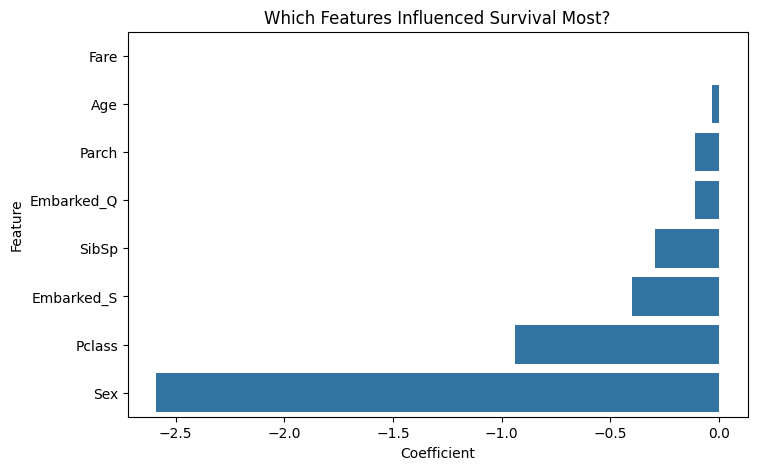

In [10]:
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_[0]
}).sort_values('Coefficient', ascending=False)

print(coefficients)

plt.figure(figsize=(8, 5))
sns.barplot(x='Coefficient', y='Feature', data=coefficients)
plt.title('Which Features Influenced Survival Most?')
plt.show()

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest = 100 decision trees voting together
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
print(f"Logistic Regression (baseline): {accuracy * 100:.1f}%")
print(f"Random Forest (comparison):     {rf_accuracy * 100:.1f}%")

Logistic Regression (baseline): 81.0%
Random Forest (comparison):     81.0%


In [12]:
print(f"""
============== MODEL SUMMARY ==============
Task:   Predict Titanic passenger survival
Model:  Logistic Regression (baseline)
Accuracy: {accuracy * 100:.1f}%

Key evaluation metrics: precision, recall, F1 (see report above)
Top features: Sex, Pclass, Fare

The model independently discovered the same patterns
as my Task 2 EDA — gender, class, and fare mattered most!
===========================================
""")


============== MODEL SUMMARY ==============
Task:   Predict Titanic passenger survival
Model:  Logistic Regression (baseline)
Accuracy: 81.0%

Key evaluation metrics: precision, recall, F1 (see report above)
Top features: Sex, Pclass, Fare

The model independently discovered the same patterns
as my Task 2 EDA — gender, class, and fare mattered most!

